In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
import matplotlib.pyplot as plt
import seaborn as sns

# Load Excel file
excel_file = '/content/drive/My Drive/Colab Notebooks/LA_Health_V2.xlsx'
df = pd.read_excel(excel_file)

# Initial Data Info
print("Columns:", df.columns.tolist())
print("Initial shape:", df.shape)

# 1. Remove Duplicates
df = df.drop_duplicates()
print("After dropping duplicates:", df.shape)

# 2. Impute Missing Values
# Numeric with mean
numeric_cols = ['Patient Age','Total Turnover','Total Cashflow','Total Outstanding']
for col in numeric_cols:
    if df[col].isnull().any():
        df[col].fillna(df[col].mean(), inplace=True)
# Categorical with mode
cat_cols = ['Service Centre','ICD10 Description','Gender']
for col in cat_cols:
    if df[col].isnull().any():
        df[col].fillna('Unknown', inplace=True)
#print("After imputing missing values:", df.shape)

# 3. Remove Outliers using IQR for numeric fields
def remove_outliers_IQR(data, columns):
    mask = pd.Series(True, index=data.index)
    for col in columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1
        low_bound = Q1 - 1.5*IQR
        high_bound = Q3 + 1.5*IQR
        mask &= (data[col] >= low_bound) & (data[col] <= high_bound)
    return data[mask]

numeric_for_outliers = ['Payment_Duration','Patient Age','Total Turnover',
                        'Total Cashflow','Total Outstanding',
                        'Total Medical Aid Outstanding','Total Patient Outstanding']
df = remove_outliers_IQR(df, numeric_for_outliers)
print("After outlier removal:", df.shape)

from google.colab import files
# Save to CSV
cleaned_file_path = "LA_Health_Cleaned.csv"
df.to_csv(cleaned_file_path, index=False)

# Download the file
files.download(cleaned_file_path)

Columns: ['Payment_Duration', 'Service Centre', 'Option', 'ICD10 Description', 'Patient Age', 'Gender', 'Specialty', 'Debtor Status', 'POSSIBLE PMB CALCULATED', 'CONTRACTED/NON-CONTRACTED', 'Total Outstanding', 'Total Medical Aid Outstanding', 'Total Patient Outstanding', 'Total Turnover', 'Total Cashflow']
Initial shape: (50000, 15)
After dropping duplicates: (34590, 15)
After outlier removal: (18967, 15)


<ipython-input-15-e72b7499a5bc>:32: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)
<ipython-input-15-e72b7499a5bc>:37: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
desc_stats.to_excel("summary_statistics.xlsx")
desc_stats = desc_stats.round(2)
print(desc_stats)

                                   Min      Max     Mean       Q1  \
Payment_Duration                  0.00    49.00    11.40     7.00   
Patient Age                      32.00    59.00    45.31    45.59   
Total Turnover                -1349.66  4564.30  1143.82   430.60   
Total Cashflow                -4413.20  1349.66 -1168.23 -1614.00   
Total Outstanding                 0.00     0.00     0.00     0.00   
Total Medical Aid Outstanding     0.00     0.00     0.00     0.00   
Total Patient Outstanding         0.00     0.00     0.00     0.00   

                               Q2 (Median)       Q3  Std Dev  
Payment_Duration                      9.00    13.00     8.92  
Patient Age                          45.59    45.59     4.99  
Total Turnover                      954.75  1538.10   913.76  
Total Cashflow                     -968.00  -439.10   901.87  
Total Outstanding                     0.00     0.00     0.00  
Total Medical Aid Outstanding         0.00     0.00     0.00  
Total 

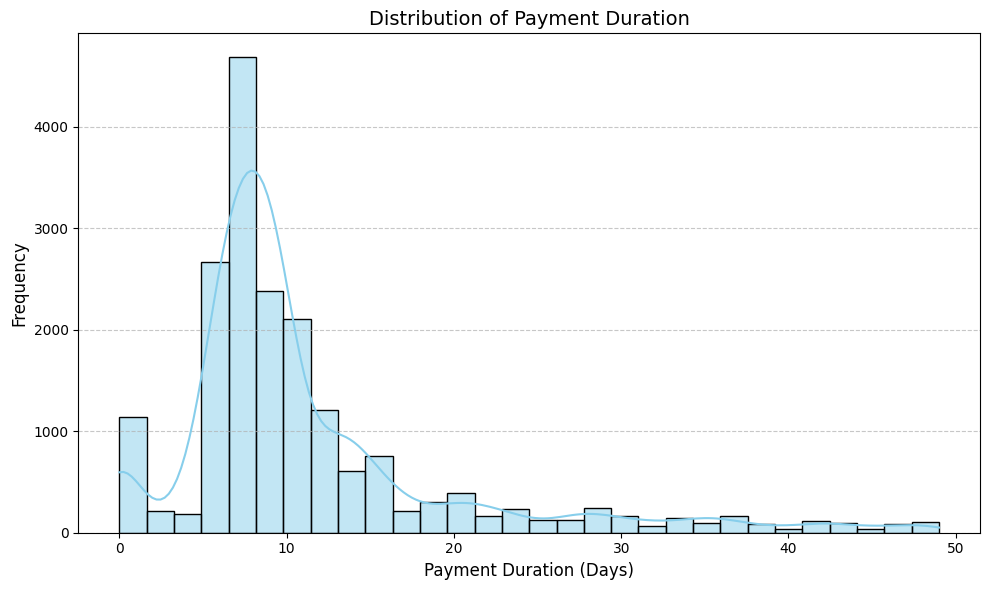

In [ ]:
# Plot histogram
plt.figure(figsize=(10, 6))
sns.histplot(df['Payment_Duration'], bins=30, kde=True, color='skyblue')
plt.title('Distribution of Payment Duration', fontsize=14)
plt.xlabel('Payment Duration (Days)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()



In [ ]:
# Table 2: Group by PMB status
table2 = df.groupby('POSSIBLE PMB CALCULATED').agg(
    Mean_Payment_Duration=('Payment_Duration', 'mean'),
    Median_Payment_Duration=('Payment_Duration', 'median'),
    Number_of_Claims=('Payment_Duration', 'count')
).reset_index()

# Rename PMB field for clarity if needed
table2.rename(columns={'POSSIBLE PMB CALCULATED': 'PMB Status'}, inplace=True)
print("Table 2: Average Payment Duration by PMB Status")
print(table2)

# Table 3: Group by Contract Status
table3 = df.groupby('CONTRACTED/NON-CONTRACTED').agg(
    Mean_Payment_Duration=('Payment_Duration', 'mean'),
    Median_Payment_Duration=('Payment_Duration', 'median'),
    Number_of_Claims=('Payment_Duration', 'count')
).reset_index()

# Rename Contract Status field for clarity
table3.rename(columns={'CONTRACTED/NON-CONTRACTED': 'Contract Status'}, inplace=True)
print("\nTable 3: Average Payment Duration by Contract Status")
print(table3)

Table 2: Average Payment Duration by PMB Status
  PMB Status  Mean_Payment_Duration  Median_Payment_Duration  Number_of_Claims
0    NON-PMB              10.614221                      8.0              5555
1        PMB              11.731509                      9.0             13412

Table 3: Average Payment Duration by Contract Status
  Contract Status  Mean_Payment_Duration  Median_Payment_Duration  \
0      CONTRACTED              10.816766                      9.0   
1  NON-CONTRACTED              15.223013                     10.0   

   Number_of_Claims  
0             16438  
1              2529  


In [ ]:
# Group by Service Centre and calculate mean Payment Duration and number of claims
top_10_centers = df.groupby('Service Centre').agg(
    Mean_Payment_Duration=('Payment_Duration', 'mean'),
    Number_of_Claims=('Payment_Duration', 'count')
).reset_index()

# Sort and get the top 10
top_10_centers = top_10_centers.sort_values(by='Mean_Payment_Duration', ascending=False).head(10)

# Export to Excel
top_10_centers.to_excel("Top10_ServiceCenters_By_PaymentDuration.xlsx", index=False)

# Display result
print("Top 10 Service Centers by Average Payment Duration")
print(top_10_centers)


Top 10 Service Centers by Average Payment Duration
                                Service Centre  Mean_Payment_Duration  \
77                             CRESCENT CLINIC              45.000000   
80                                  DAY CLINIC              43.000000   
40   BUSAMED BRAM FISCHER INT AIRPORT HOSPITAL              42.000000   
541                             UNION HOSPITAL              41.666667   
28                                  BLOCK ROOM              41.000000   
476                           ROOMS COSMO CITY              39.000000   
492    ROOMS RONDEBOSCH MEDICAL CENTRE PRIVATE              37.000000   
499                        ROUXCOR HOUSE ROOMS              36.000000   
107                EMALAHLENI PRIVATE HOSPITAL              36.000000   
297            MEDICLINIC MUELMED SUITES ROOMS              35.000000   

     Number_of_Claims  
77                  1  
80                  1  
40                  2  
541                 3  
28                  1  
4

In [ ]:
# Group by Specialty and calculate mean Payment Duration and number of claims
top_10_specialties = df.groupby('Specialty').agg(
    Mean_Payment_Duration=('Payment_Duration', 'mean'),
    Number_of_Claims=('Payment_Duration', 'count')
).reset_index()

# Sort and get the top 10
top_10_specialties = top_10_specialties.sort_values(by='Mean_Payment_Duration', ascending=False).head(10)

# Export to Excel
top_10_specialties.to_excel("Top10_Specialties_By_PaymentDuration.xlsx", index=False)

# Display result
print("Top 10 Specialties by Average Payment Duration")
print(top_10_specialties)


Top 10 Specialties by Average Payment Duration
                                        Specialty  Mean_Payment_Duration  \
49             (086 003) Educational Psychologist              36.000000   
35   (042) General Surgeon (003) Gastroenterology              20.181159   
11            (018) Physician (006) Critical Care              19.666667   
16                              (020) Neurologist              18.990741   
76                                      Dietitian              18.000000   
104               SAOPA (Orthotist & Prosthetist)              17.666667   
28       (036) Plastic and Reconstructive Surgeon              16.411765   
92                          Otorhinolaryngologist              16.000000   
26          (032) Paediatrician (009) Pulmonology              15.904762   
30                   (038) Diagnostic Radiologist              15.884615   

     Number_of_Claims  
49                  1  
35                138  
11                105  
16                10

In [ ]:
# Define target and drop from features
y = df['Payment_Duration']
X = df.drop(columns=['Payment_Duration'])

# One-hot encode categorical columns
categorical_cols = X.select_dtypes(include=['category', 'object']).columns
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=50)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

# Initialize regression models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=50),
    'Gradient Boosting': GradientBoostingRegressor(random_state=50),
    #'Neural Network': MLPRegressor(max_iter=1000, random_state=50),
    'Lasso Regression': LassoCV(cv=5, random_state=50, max_iter=10000),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=50),

}


# Feature selection (top 50)
selector = SelectKBest(score_func=f_regression, k=50)
X_selected = selector.fit_transform(X, y)
selected_columns = X.columns[selector.get_support()]
print("Top selected features:")
print(selected_columns)

# Train, predict, and evaluate each model
for name, model in models.items():
    print(f"\nTraining and evaluating model: {name}")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"Mean Squared Error (MSE): {mse:.2f}")
    print(f"Mean Absolute Error (MAE): {mae:.2f}")
    print(f"R² Score: {r2:.4f}")



Train shape: (13276, 2357) Test shape: (5691, 2357)
Top selected features:
Index(['Total Cashflow',
       'Service Centre_BUSAMED BRAM FISCHER INT AIRPORT HOSPITAL',
       'Service Centre_CITY HOSPITAL DURBAN',
       'Service Centre_DURBAN MEDICAL CENTRE',
       'Service Centre_EMPANGENI ROOMS', 'Service Centre_HOSPITAL - HOSPITAAL',
       'Service Centre_LENMED AHMED KATHRADA PRIVATE HOSPITAL',
       'Service Centre_LIFE GARDEN CLINIC HOSPITAL',
       'Service Centre_LIFE MERCANTILE HOSPITAL PE',
       'Service Centre_LIFE VINCENT PALLOTTI HOSPITAL',
       'Service Centre_MEDICLINIC CONSTANTIABERG',
       'Service Centre_MILPARK HOSPITAL',
       'Service Centre_NETCARE CLINTON HOSPITAL',
       'Service Centre_NETCARE ST AUGUSTINES HOSPITAL',
       'Service Centre_RICHARDS BAY MELOMED HOSPITAL',
       'Service Centre_UNION HOSPITAL', 'Service Centre_Unknown',
       'Service Centre_VICTORIA ROOMS',
       'ICD10 Description_Acute respiratory failure, Type I [hypoxic]',
  

<ipython-input-85-9e59db7caadf>:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importances, palette='viridis')


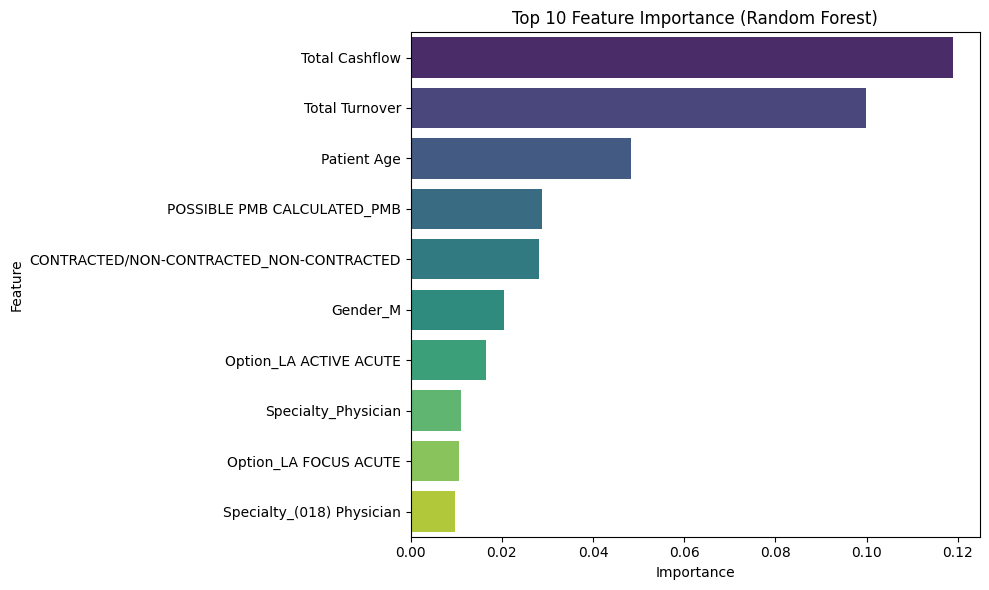

In [ ]:
# --- Feature Importance from Random Forest ---
rf_model = models['Random Forest']
rf_importances = rf_model.feature_importances_
feature_importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_importances
}).sort_values(by='Importance', ascending=False).head(10)

# --- Plot Top 10 Feature Importances ---
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importances, palette='viridis')
plt.title('Top 10 Feature Importance (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('feature_importance.png')
plt.show()




In [16]:
# 0. Load the cleaned dataset
df_cleaned = pd.read_excel('/content/drive/My Drive/Colab Notebooks/LA_Health_Cleaned.xlsx')

# 1. Define target and features
y = df_cleaned['Payment_Duration']
X = df_cleaned.drop(columns=['Payment_Duration'])

# 2. One-hot encode categorical variables
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# 3. Feature Selection (top 50)
selector_full = SelectKBest(score_func=f_regression, k=50)
X_selected_full = selector_full.fit_transform(X, y)
selected_columns_full = X.columns[selector_full.get_support()]

# 4. Fit Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=50)
rf_model.fit(X_selected_full, y)

# 5. Predict using full cleaned dataset
y_pred_full = rf_model.predict(X_selected_full)

# 6. Reload the original unprocessed dataset
csv_file = '/content/drive/My Drive/Colab Notebooks/LA_Health_V3.xlsx'
original_data_full = pd.read_excel(csv_file).reset_index(drop=True)

# 7. Create prediction DataFrame and align index
prediction_df = pd.DataFrame({'Predicted_Payment_Duration': y_pred_full})
prediction_df.index = df_cleaned.index  # ensure correct alignment

# 8. Merge predictions into original data
merged_data = original_data_full.copy()
merged_data.loc[prediction_df.index, 'Predicted_Payment_Duration'] = prediction_df['Predicted_Payment_Duration']

# 9. Drop index column if exists
if 'index' in merged_data.columns:
    merged_data.drop(columns=['index'], inplace=True)

# 10. Save to Excel
output_file_path = '/content/drive/My Drive/Colab Notebooks/LA_Health_V3_Predictions.xlsx'
merged_data.to_excel(output_file_path, index=False)

print(f"✅ Full dataset with Random Forest predictions saved to: {output_file_path}")

✅ Full dataset with Random Forest predictions saved to: /content/drive/My Drive/Colab Notebooks/LA_Health_V3_Predictions.xlsx
